# k-Nearest Neighbours
## Machine Learning — BS Computer Science 3(3-0)



| | |
|---|---|
| **Notebook** | `NB05_KNN.ipynb` |
| **Lecture** | Lecture 7 (Week 3) |
| **CLO** | CLO-2 |
| **Dataset** | Iris / Wine |

**Objective.** Meet the bias–variance trade-off, decision boundaries and the curse of dimensionality in the simplest possible model.

**By the end of this notebook you will be able to:**

1. Build a scaler + k-NN pipeline and plot its decision regions.
2. Produce a validation curve of train and test accuracy against k.
3. Demonstrate that scaling decides the answer for distance-based models.
4. Show that irrelevant features degrade k-NN sharply.

---

## 0. Setup and reproducibility

In [1]:
# ---------------------------------------------------------------------
# Reproducibility header — required in EVERY notebook you submit
# ---------------------------------------------------------------------
import sys, numpy as np, pandas as pd, sklearn, matplotlib
import matplotlib.pyplot as plt

print('python      ', sys.version.split()[0])
print('numpy       ', np.__version__)
print('pandas      ', pd.__version__)
print('scikit-learn', sklearn.__version__)
print('matplotlib  ', matplotlib.__version__)

RANDOM_STATE = 1
rng = np.random.default_rng(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

python       3.13.7
numpy        2.3.5
pandas       2.3.3
scikit-learn 1.7.2
matplotlib   3.10.7


In [2]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from matplotlib.colors import ListedColormap

## 1. A reusable decision-region plotter

Keep this helper — it is used in almost every classification notebook from here on.

In [5]:
def plot_decision_regions(X, y, model, ax=None, resolution=0.02, title=''):
    markers = ('o', 's', '^', 'v', '<')
    colors  = ('#E74C3C', '#3498DB', '#2ECC71', '#9B59B6', '#F39C12')
    cmap = ListedColormap(colors[:len(np.unique(y))])
    ax = ax or plt.gca()

    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    Z = model.predict(np.c_[xx1.ravel(), xx2.ravel()]).reshape(xx1.shape)
    ax.contourf(xx1, xx2, Z, alpha=0.25, cmap=cmap)

    for idx, cl in enumerate(np.unique(y)):
        ax.scatter(X[y == cl, 0], X[y == cl, 1], c=colors[idx],
                   marker=markers[idx], edgecolor='black', s=35,
                   label=f'class {cl}')
    ax.set_title(title)
    ax.legend(loc='best', fontsize=8)
    return ax

## 2. k as the complexity dial

Small k gives a jagged boundary that follows every noisy point; large k flattens the boundary until the model predicts the majority class everywhere.

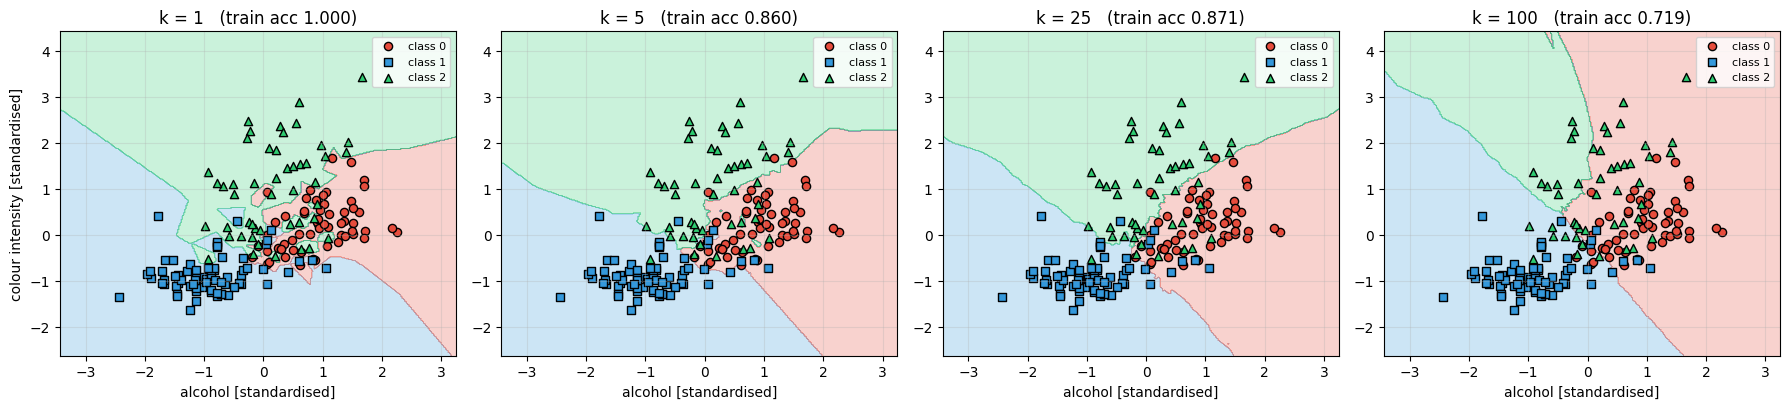

In [6]:
wine = load_wine()
X2 = StandardScaler().fit_transform(wine.data[:, [0, 9]])   # two features to plot
y2 = wine.target

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, k in zip(axes, (1, 5, 25, 100)):
    knn = KNeighborsClassifier(n_neighbors=k).fit(X2, y2)
    plot_decision_regions(X2, y2, knn, ax=ax,
                          title=f'k = {k}   (train acc {knn.score(X2, y2):.3f})')
    ax.set_xlabel('alcohol [standardised]')
axes[0].set_ylabel('colour intensity [standardised]')
plt.tight_layout(); plt.show()

**Note the k = 1 panel.** Its training accuracy is exactly 1.000, because the nearest neighbour of a training point is the point itself at distance 0. The number is guaranteed by construction and carries no information whatsoever.

## 3. Compute a prediction by hand

Verify your arithmetic from the lecture worked example before trusting the library.

In [7]:
train_pts = np.array([[1, 1], [2, 1], [4, 4], [5, 4], [3, 3]])
train_lab = np.array(['Red', 'Red', 'Blue', 'Blue', 'Blue'])
query = np.array([2.5, 2.5])

d = np.linalg.norm(train_pts - query, axis=1)
order = np.argsort(d)

display(pd.DataFrame({'point': [tuple(p) for p in train_pts],
                      'label': train_lab,
                      'distance': d.round(3)}).sort_values('distance'))

for k in (1, 3, 5):
    votes = pd.Series(train_lab[order[:k]]).value_counts()
    print(f'k = {k}: neighbours {list(train_lab[order[:k]])} -> {votes.idxmax()}')

,point,label,distance
4,"(3, 3)",Blue,0.707
1,"(2, 1)",Red,1.581
2,"(4, 4)",Blue,2.121
0,"(1, 1)",Red,2.121
3,"(5, 4)",Blue,2.915


k = 1: neighbours [np.str_('Blue')] -> Blue
k = 3: neighbours [np.str_('Blue'), np.str_('Red'), np.str_('Blue')] -> Blue
k = 5: neighbours [np.str_('Blue'), np.str_('Red'), np.str_('Blue'), np.str_('Red'), np.str_('Blue')] -> Blue


> One query, three different answers. **k is a hyperparameter: it defines the model, and it must be selected on validation data — never by eye and never on the test set.**

## 4. The validation curve

x-axis is model complexity; the two curves diverge exactly where overfitting begins. Note that `k` is chosen by **cross-validation on the training set**, not from the test curve.

C:\Users\User\PycharmProjects\PythonProject\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:971: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "C:\Users\User\PycharmProjects\PythonProject\.venv\Lib\site-packages\sklearn\metrics\_scorer.py", line 156, in __call__
    score = scorer(estimator, *args, **routed_params.get(name).score)
  File "C:\Users\User\PycharmProjects\PythonProject\.venv\Lib\site-packages\sklearn\metrics\_scorer.py", line 492, in __call__
    return estimator.score(*args, **kwargs)
           ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "C:\Users\User\PycharmProjects\PythonProject\.venv\Lib\site-packages\sklearn\pipeline.py", line 1189, in score
    return self.steps[-1][1].score(Xt, y, **score_params)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\User\PycharmProjects\PythonProject\.venv\Lib\site-packages\sklearn\neig

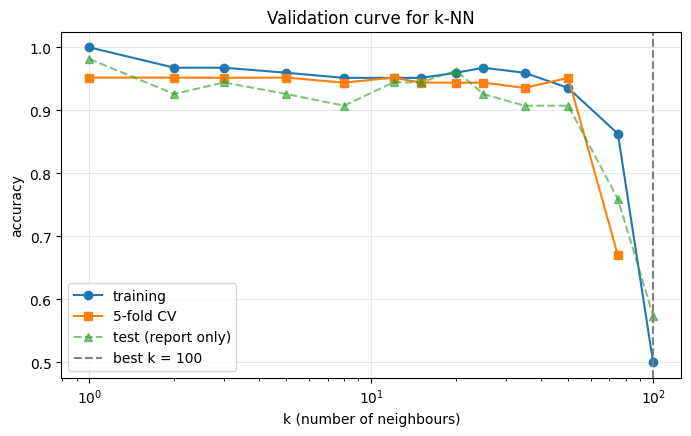

In [8]:
X, y = wine.data, wine.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

ks = [1, 2, 3, 5, 8, 12, 15, 20, 25, 35, 50, 75, 100]
tr, cv, te = [], [], []
for k in ks:
    p = Pipeline([('sc', StandardScaler()),
                  ('knn', KNeighborsClassifier(n_neighbors=k))])
    p.fit(X_train, y_train)
    tr.append(p.score(X_train, y_train))
    te.append(p.score(X_test, y_test))
    cv.append(cross_val_score(p, X_train, y_train, cv=5).mean())

plt.plot(ks, tr, 'o-', label='training')
plt.plot(ks, cv, 's-', label='5-fold CV')
plt.plot(ks, te, '^--', label='test (report only)', alpha=0.6)
plt.axvline(ks[int(np.argmax(cv))], ls='--', c='grey',
            label=f'best k = {ks[int(np.argmax(cv))]}')
plt.xlabel('k (number of neighbours)'); plt.ylabel('accuracy')
plt.xscale('log'); plt.legend(); plt.title('Validation curve for k-NN')
plt.show()

## 5. Experiment — scaling and the curse of dimensionality

In [9]:
def evaluate(Xtr, Xte, scale=True, k=5):
    steps = ([('sc', StandardScaler())] if scale else []) + \
            [('knn', KNeighborsClassifier(n_neighbors=k))]
    p = Pipeline(steps).fit(Xtr, y_train)
    return p.score(Xte, y_test)

# add 20 columns of pure noise
noise_tr = rng.normal(size=(X_train.shape[0], 20))
noise_te = rng.normal(size=(X_test.shape[0], 20))
Xn_tr = np.hstack([X_train, noise_tr])
Xn_te = np.hstack([X_test,  noise_te])

rows = [
    {'variant': 'baseline (scaled)',        'test': evaluate(X_train, X_test, True)},
    {'variant': 'no scaling',               'test': evaluate(X_train, X_test, False)},
    {'variant': '+20 noise features',       'test': evaluate(Xn_tr, Xn_te, True)},
    {'variant': '+20 noise, no scaling',    'test': evaluate(Xn_tr, Xn_te, False)},
]
display(pd.DataFrame(rows).round(3))

,variant,test
0,baseline (scaled),0.926
1,no scaling,0.648
2,+20 noise features,0.870
3,"+20 noise, no scaling",0.648


### Interpretation — three questions

1. Why does removing the scaler hurt k-NN, when it would not hurt a decision tree?
2. The 20 noise columns carry no information at all. Why does adding them *reduce* accuracy rather than leaving it unchanged?
3. `weights='distance'` weights each neighbour by 1/distance. Add that variant to the table and say whether it helps, and for which values of k you would expect it to help most.

1.Scaling: k-NN uses distances, so features with larger values can dominate the calculation when scaling is removed. Decision trees generally do not require scaling because they use feature-based splitting instead of distance calculations.

2.Noise features: Adding 20 irrelevant features introduces random values into distance calculations. This makes the nearest neighbours less meaningful and can reduce accuracy. This problem is known as the curse of dimensionality.

3.Distance weighting: weights='distance' gives closer neighbours more voting importance than farther neighbours. It may improve accuracy for some values of k, particularly when closer neighbours are more reliable, but improvement is not guaranteed. The results should be compared experimentally.

---
## Deliverable

Decision-region plots for four values of k, the hand calculation verified against the library, the validation curve with the chosen k marked, and the four-row experiment table with all three interpretations.

---
## Submission checklist

Tick every box before you submit. Items 1–6 are the course reproducibility
rules from Lecture 3 and are marked in the rubric.

- [ ] The random seed is fixed **and printed**
- [ ] Library versions are printed in the first cell
- [ ] The raw data file was **not** modified
- [ ] Preprocessing happens **after** the split, inside a `Pipeline`
- [ ] The dataset source and licence are stated in a markdown cell
- [ ] **Kernel → Restart & Run All** completes without error
- [ ] Every experiment is followed by a written interpretation
- [ ] At least one wrong prediction or failure case is explained
- [ ] Results are reported as **mean ± standard deviation** where cross-validated
- [ ] Every plot has axis labels with units and a legend
